In [2]:
# Install required packages (run once)
%pip install scanpy anndata scrublet celltypist xgboost shap gseapy scikit-learn tensorflow matplotlib seaborn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import scanpy as sc
import anndata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sc.settings.verbosity = 1
np.random.seed(42)

In [4]:
import os
for f in os.listdir(r"C:\Users\user\OneDrive\Documents\project"):
    if f.endswith(".h5"):
        print(f)

pbmc_unsorted_10k_raw_feature_bc_matrix.h5
pbmc_unsorted_3k_filtered_feature_bc_matrix.h5
sc5p_v2_hs_PBMC_10k_multi_5gex_5fb_b_t_count_filtered_feature_bc_matrix.h5


In [5]:
DATA_PATH = r"C:\Users\user\OneDrive\Documents\project\sc5p_v2_hs_PBMC_10k_multi_5gex_5fb_b_t_count_filtered_feature_bc_matrix.h5"

adata = sc.read_10x_h5(DATA_PATH)
adata.var_names_make_unique()
adata = adata[:, adata.var['feature_types'] == 'Gene Expression'].copy()
print(adata)

AnnData object with n_obs × n_vars = 10548 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence'


In [6]:
print(adata.var['feature_types'].value_counts())

feature_types
Gene Expression    36601
Name: count, dtype: int64


In [7]:
# Basic gene/cell filtering
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

# Mitochondrial, ribosomal, hemoglobin gene flags
adata.var['mt']   = adata.var_names.str.startswith('MT-')
adata.var['ribo'] = adata.var_names.str.startswith(('RPS', 'RPL'))
adata.var['hb']   = adata.var_names.str.contains('^HB[^P]', regex=True)

sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo', 'hb'], inplace=True, percent_top=None)

print(adata)

AnnData object with n_obs × n_vars = 10529 × 20226
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'


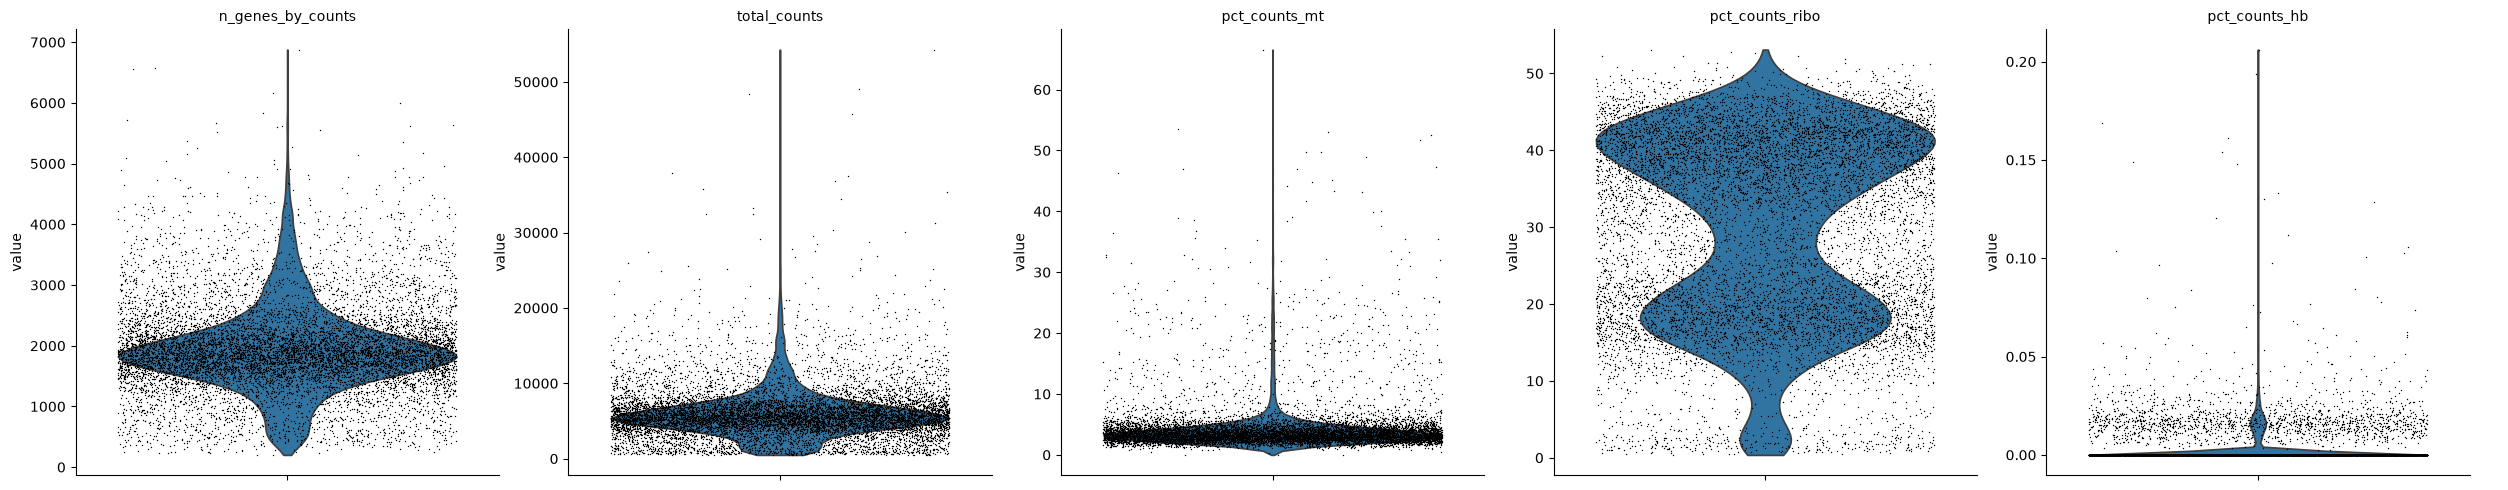

In [8]:
# QC violin plots (PI-requested)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt',
                      'pct_counts_ribo', 'pct_counts_hb'],
             jitter=0.4, multi_panel=True)

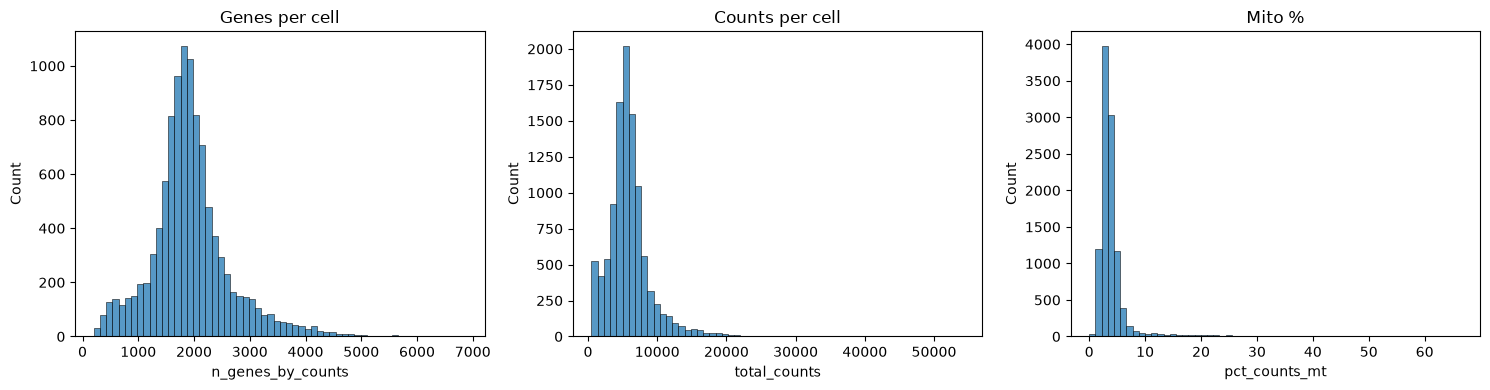

In [9]:
# QC distribution histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(adata.obs['n_genes_by_counts'], bins=60, ax=axes[0]); axes[0].set_title('Genes per cell')
sns.histplot(adata.obs['total_counts'], bins=60, ax=axes[1]); axes[1].set_title('Counts per cell')
sns.histplot(adata.obs['pct_counts_mt'], bins=60, ax=axes[2]); axes[2].set_title('Mito %')
plt.tight_layout()
plt.show()

In [10]:
print("Before adata_qc_all copy:", adata.shape)
adata_qc_all = adata.copy()
print("adata_qc_all shape:", adata_qc_all.shape)

Before adata_qc_all copy: (10529, 20226)
adata_qc_all shape: (10529, 20226)


In [11]:
# Run this right after calculate_qc_metrics, BEFORE the filtering cell
adata_qc_all = adata.copy()   # full cell set, before hard QC cutoff removes anything

In [12]:
adata = adata[(adata.obs['n_genes_by_counts'] > 200) &
              (adata.obs['n_genes_by_counts'] < 6000) &
              (adata.obs['pct_counts_mt'] < 15)].copy()
print("adata after filtering:", adata.shape)

adata after filtering: (10232, 20226)


In [13]:
import scrublet as scr

scrub = scr.Scrublet(adata.X)
doublet_scores, predicted_doublets = scrub.scrub_doublets()

adata.obs['doublet_score'] = doublet_scores
adata.obs['predicted_doublet'] = predicted_doublets

print("Doublets detected:", adata.obs['predicted_doublet'].sum())

# Remove doublets
adata = adata[~adata.obs['predicted_doublet']].copy()
print("Cells remaining:", adata.n_obs)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.34
Detected doublet rate = 4.5%
Estimated detectable doublet fraction = 55.8%
Overall doublet rate:
	Expected   = 10.0%
	Estimated  = 8.1%
Elapsed time: 27.7 seconds
Doublets detected: 463
Cells remaining: 9769


In [14]:
# Keep a copy of raw counts for later (e.g. CellTypist needs raw/normalized-to-1e4 log data)
adata.layers['counts'] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata  # store full log-normalized matrix before HVG subsetting

print(adata)

AnnData object with n_obs × n_vars = 9769 × 20226
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


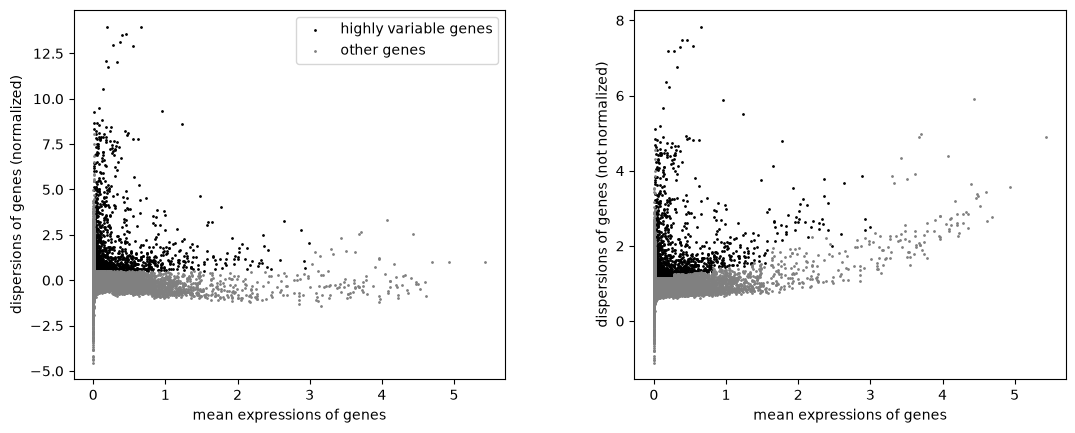

Number of HVGs: 1807


In [15]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)
print("Number of HVGs:", adata.var['highly_variable'].sum())

In [16]:
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
print(adata)

AnnData object with n_obs × n_vars = 9769 × 1807
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'
    layers: 'counts'


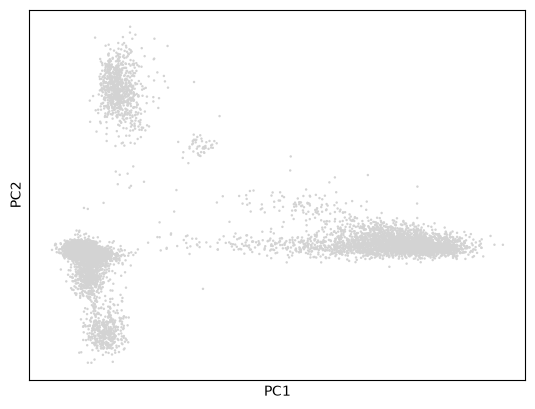

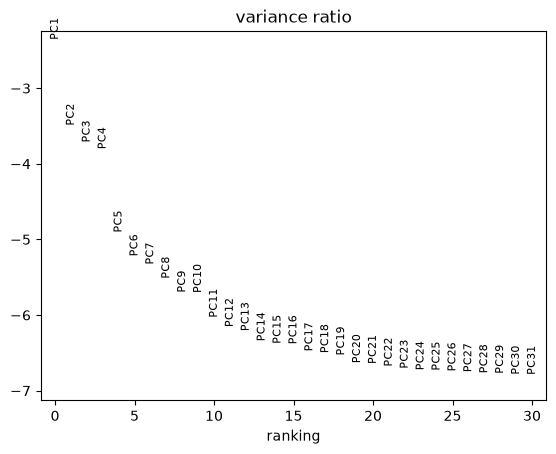

In [17]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca(adata)
sc.pl.pca_variance_ratio(adata, log=True)

In [18]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata)
sc.tl.tsne(adata)  # optional, as noted by PI

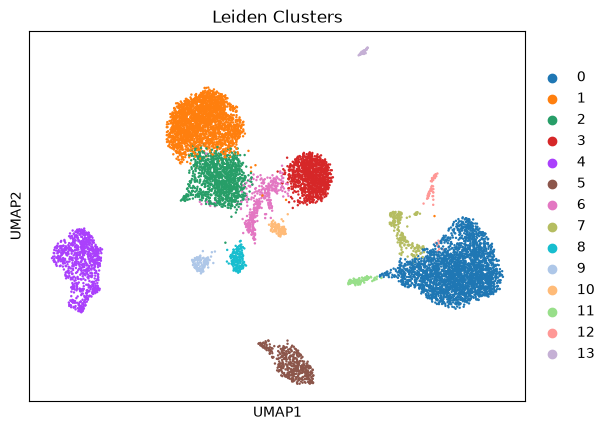

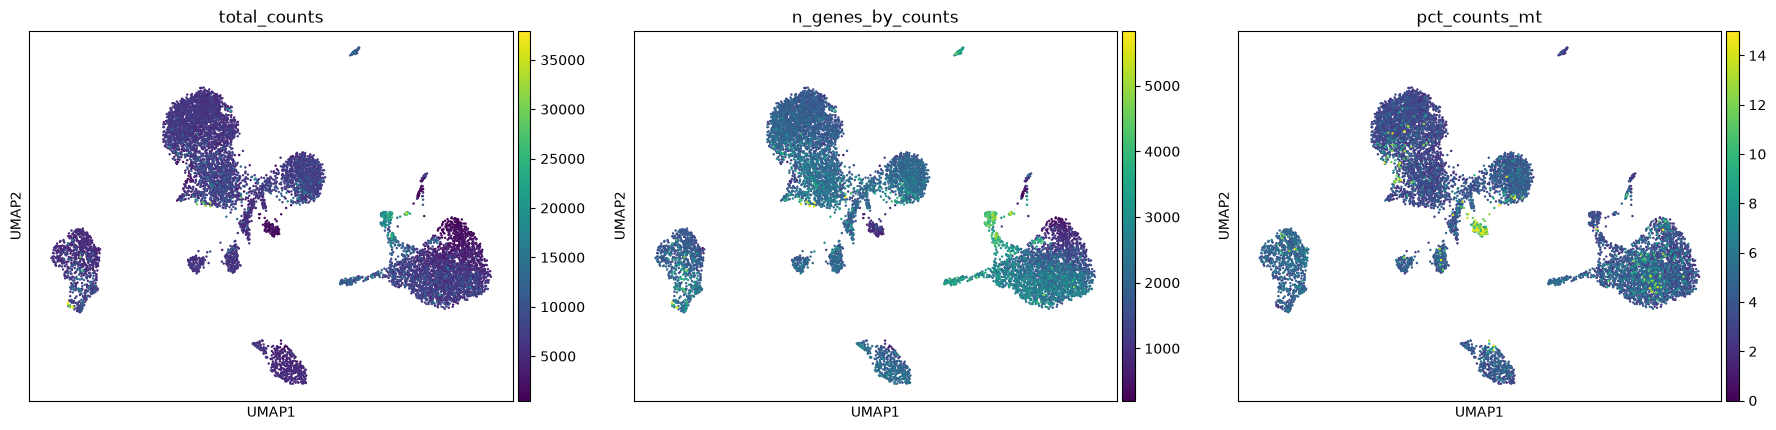

In [19]:
sc.tl.leiden(adata, resolution=0.5)

sc.pl.umap(adata, color=['leiden'], title='Leiden Clusters')
sc.pl.umap(adata, color=['total_counts', 'n_genes_by_counts', 'pct_counts_mt'])

In [20]:
%pip install celltypist

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


📂 Storing models in C:\Users\user\.celltypist\data\models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)


🔬 Input data has 9769 cells and 20226 genes
🔗 Matching reference genes in the model
🧬 5652 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


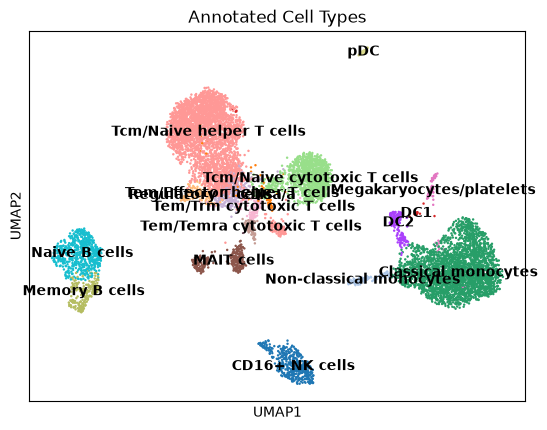

cell_type
Tcm/Naive helper T cells       3239
Classical monocytes            2823
Tcm/Naive cytotoxic T cells    1152
Naive B cells                   624
CD16+ NK cells                  427
MAIT cells                      286
Tem/Effector helper T cells     225
Memory B cells                  216
DC2                             144
Regulatory T cells              128
Tem/Trm cytotoxic T cells       125
Non-classical monocytes         115
Tem/Temra cytotoxic T cells      80
Megakaryocytes/platelets         62
CD8a/a                           54
pDC                              50
DC1                              19
Name: count, dtype: int64


In [21]:
import celltypist
from celltypist import models

models.download_models(model=['Immune_All_Low.pkl'])

# CellTypist expects log1p-normalized-to-10k data with all genes (use adata.raw)
adata_full = adata.raw.to_adata()
predictions = celltypist.annotate(adata_full, model='Immune_All_Low.pkl', majority_voting=True)

adata.obs['cell_type'] = predictions.predicted_labels['majority_voting'].values

sc.pl.umap(adata, color='cell_type', legend_loc='on data', title='Annotated Cell Types')
print(adata.obs['cell_type'].value_counts())

In [22]:
adata_qc_all.obs['cell_quality'] = np.where(
    (adata_qc_all.obs['n_genes_by_counts'] > 200) &
    (adata_qc_all.obs['n_genes_by_counts'] < 6000) &
    (adata_qc_all.obs['pct_counts_mt'] < 15),
    'Good', 'Bad'
)

adata_qc_all.obs['gene_complexity']  = adata_qc_all.obs['n_genes_by_counts'] / adata_qc_all.obs['total_counts']
adata_qc_all.obs['log_total_counts'] = np.log1p(adata_qc_all.obs['total_counts'])
adata_qc_all.obs['mt_ratio']         = adata_qc_all.obs['pct_counts_mt'] / 100
adata_qc_all.obs['ribo_ratio']       = adata_qc_all.obs['pct_counts_ribo'] / 100
adata_qc_all.obs['mt_ribo_ratio']    = adata_qc_all.obs['mt_ratio'] / (adata_qc_all.obs['ribo_ratio'] + 1e-6)

print(adata_qc_all.obs[['cell_quality', 'gene_complexity', 'log_total_counts',
                          'mt_ratio', 'ribo_ratio', 'mt_ribo_ratio']].head())

                   cell_quality  gene_complexity  log_total_counts  mt_ratio  \
AAACCTGAGACAGACC-1         Good         0.417053          8.466110  0.042526   
AAACCTGAGCGATAGC-1         Good         0.305358          8.660081  0.019247   
AAACCTGAGCGGCTTC-1         Good         0.391984          8.515391  0.025050   
AAACCTGAGGATCGCA-1         Good         0.384129          8.701512  0.036932   
AAACCTGAGTCACGCC-1         Good         0.318563          8.891236  0.021742   

                    ribo_ratio  mt_ribo_ratio  
AAACCTGAGACAGACC-1    0.133474       0.318610  
AAACCTGAGCGATAGC-1    0.423791       0.045417  
AAACCTGAGCGGCTTC-1    0.231463       0.108225  
AAACCTGAGGATCGCA-1    0.176343       0.209433  
AAACCTGAGTCACGCC-1    0.336590       0.064595  


In [23]:
feature_cols = [
    'total_counts', 'pct_counts_ribo', 'pct_counts_hb',
    'gene_complexity', 'log_total_counts', 'ribo_ratio', 'mt_ribo_ratio'
]

X = adata_qc_all.obs[feature_cols].copy()
y = adata_qc_all.obs['cell_quality'].copy()

print(X.shape)
print(y.value_counts())

(10529, 7)
cell_quality
Good    10232
Bad       297
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(X_train.shape, X_test.shape)

(8423, 7) (2106, 7)


In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 20, None]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid, cv=cv, scoring='f1_macro', n_jobs=-1
)
rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_
print("Best RF params:", rf_grid.best_params_)

rf_cv_scores = cross_val_score(rf_best, X_train, y_train, cv=cv, scoring='accuracy')
print("RF 5-fold CV accuracy: %.4f +/- %.4f" % (rf_cv_scores.mean(), rf_cv_scores.std()))

Best RF params: {'max_depth': 20, 'n_estimators': 100}
RF 5-fold CV accuracy: 0.9938 +/- 0.0010


In [26]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)   # Good/Bad -> 1/0
y_test_enc  = le.transform(y_test)

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 8],
    'learning_rate': [0.01, 0.1, 0.2]
}

xgb_grid = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),
    xgb_param_grid, cv=cv, scoring='f1_macro', n_jobs=-1
)
xgb_grid.fit(X_train, y_train_enc)

xgb_best = xgb_grid.best_estimator_
print("Best XGBoost params:", xgb_grid.best_params_)

Best XGBoost params: {'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 100}


In [27]:
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

nn_model = tf.keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = nn_model.fit(
    X_train_scaled, y_train_enc,
    validation_split=0.1,
    epochs=30, batch_size=32, verbose=0
)

print("Final training accuracy:", history.history['accuracy'][-1])
print("Final validation accuracy:", history.history['val_accuracy'][-1])

TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.


Final training accuracy: 0.9920844435691833
Final validation accuracy: 0.9857650995254517


In [28]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
)

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_prob)
    }

results = []

# --- Random Forest ---
rf_pred = rf_best.predict(X_test)
rf_pred_enc = le.transform(rf_pred)
rf_prob = rf_best.predict_proba(X_test)[:, list(rf_best.classes_).index('Good')]
results.append(evaluate_model('Random Forest', y_test_enc, rf_pred_enc, rf_prob))

# --- XGBoost ---
xgb_pred_enc = xgb_best.predict(X_test)
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]
results.append(evaluate_model('XGBoost', y_test_enc, xgb_pred_enc, xgb_prob))

# --- Neural Network ---
nn_prob = nn_model.predict(X_test_scaled).ravel()
nn_pred_enc = (nn_prob > 0.5).astype(int)
results.append(evaluate_model('Neural Network', y_test_enc, nn_pred_enc, nn_prob))

results_df = pd.DataFrame(results)
print(results_df)

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
            Model  Accuracy  Precision    Recall        F1       AUC
0   Random Forest  0.993352   0.996580  0.996580  0.996580  0.998820
1         XGBoost  0.994302   0.998042  0.996092  0.997066  0.999015
2  Neural Network  0.991928   0.996575  0.995115  0.995845  0.998286


In [29]:
from sklearn.metrics import classification_report

print("Random Forest:\n", classification_report(y_test_enc, rf_pred_enc, target_names=le.classes_))
print("\nXGBoost:\n", classification_report(y_test_enc, xgb_pred_enc, target_names=le.classes_))
print("\nNeural Network:\n", classification_report(y_test_enc, nn_pred_enc, target_names=le.classes_))

Random Forest:
               precision    recall  f1-score   support

         Bad       0.88      0.88      0.88        59
        Good       1.00      1.00      1.00      2047

    accuracy                           0.99      2106
   macro avg       0.94      0.94      0.94      2106
weighted avg       0.99      0.99      0.99      2106


XGBoost:
               precision    recall  f1-score   support

         Bad       0.87      0.93      0.90        59
        Good       1.00      1.00      1.00      2047

    accuracy                           0.99      2106
   macro avg       0.94      0.96      0.95      2106
weighted avg       0.99      0.99      0.99      2106


Neural Network:
               precision    recall  f1-score   support

         Bad       0.84      0.88      0.86        59
        Good       1.00      1.00      1.00      2047

    accuracy                           0.99      2106
   macro avg       0.92      0.94      0.93      2106
weighted avg       0.99      

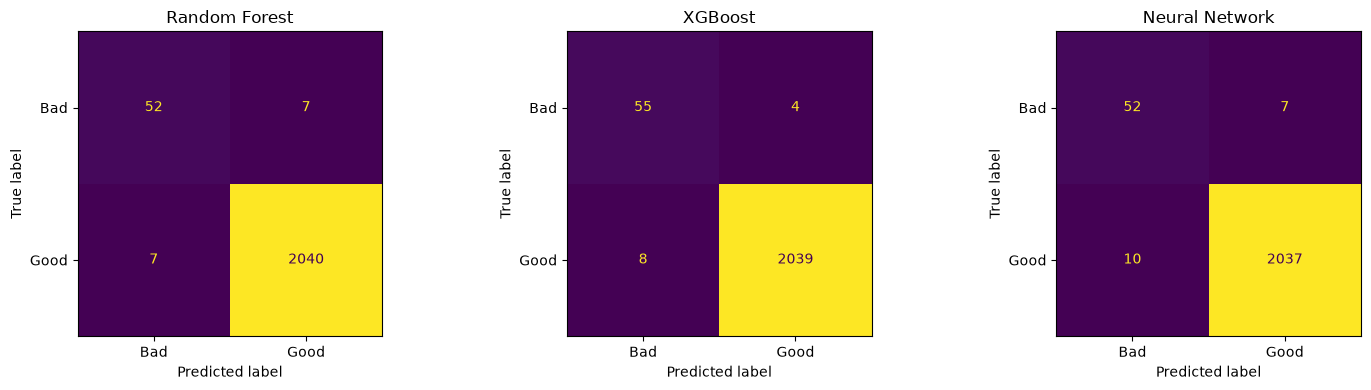

In [30]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, [('Random Forest', rf_pred_enc),
                                    ('XGBoost', xgb_pred_enc),
                                    ('Neural Network', nn_pred_enc)]):
    cm = confusion_matrix(y_test_enc, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Bad', 'Good']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

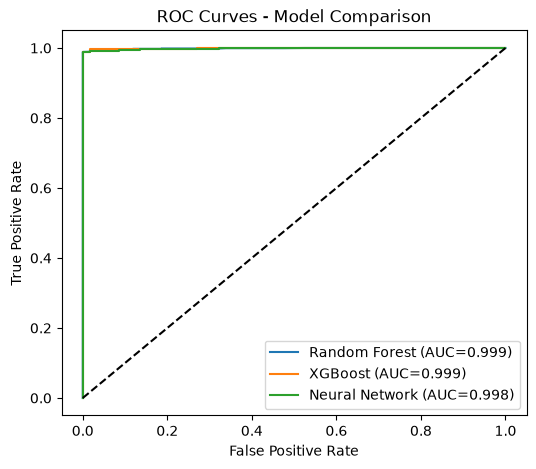

In [31]:
# ROC curves
plt.figure(figsize=(6, 5))
for name, prob in [('Random Forest', rf_prob), ('XGBoost', xgb_prob), ('Neural Network', nn_prob)]:
    fpr, tpr, _ = roc_curve(y_test_enc, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.show()

Best model by F1: XGBoost


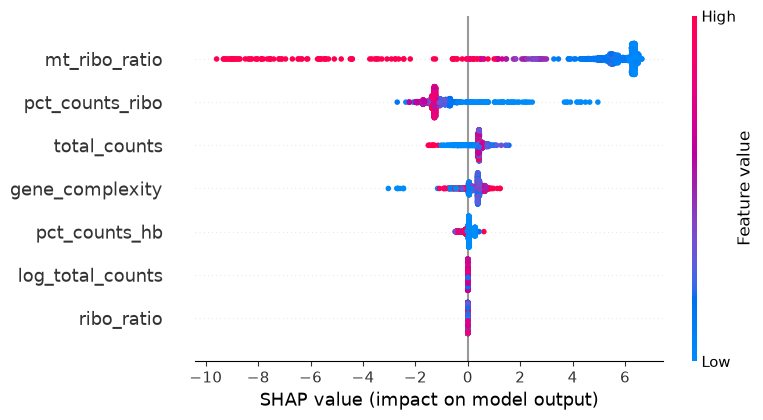

In [32]:
import shap

best_model_name = results_df.sort_values('F1', ascending=False).iloc[0]['Model']
print("Best model by F1:", best_model_name)

# Using XGBoost as the tree-based reference explainer (swap to rf_best if RF wins)
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=True)

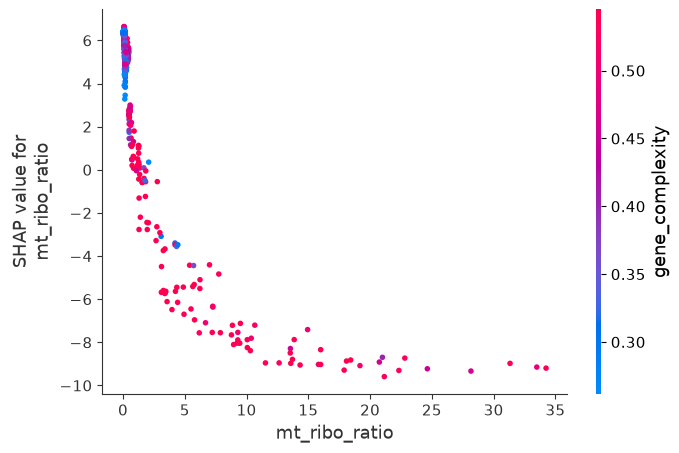

In [33]:
# SHAP dependence plot for the top feature
top_feature = X_test.columns[np.argsort(np.abs(shap_values).mean(0))[-1]]
shap.dependence_plot(top_feature, shap_values, X_test)

                Configuration        F1       AUC
0           A. All 7 features  0.997066  0.999015
1    B. Without mt_ribo_ratio  0.993649  0.995371
2  C. Without pct_counts_ribo  0.997066  0.999015
3             D. Without both  0.993649  0.995371


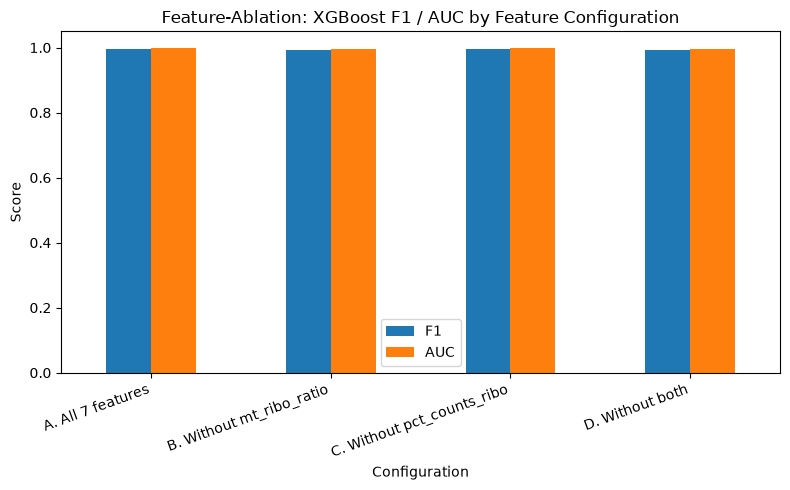


Saved: Feature_Ablation_Results.csv


In [34]:
# Feature-ablation experiment: A (all 7) / B (no mt_ribo_ratio) / C (no pct_counts_ribo) / D (no both)

ablation_configs = {
    'A. All 7 features':              feature_cols,
    'B. Without mt_ribo_ratio':        [f for f in feature_cols if f != 'mt_ribo_ratio'],
    'C. Without pct_counts_ribo':      [f for f in feature_cols if f != 'pct_counts_ribo'],
    'D. Without both':                 [f for f in feature_cols if f not in ('mt_ribo_ratio', 'pct_counts_ribo')],
}

ablation_results = []

for config_name, cols in ablation_configs.items():
    # Reuse the best hyperparameters already found for the full feature set,
    # so every configuration is compared on equal footing rather than re-tuned individually.
    model = XGBClassifier(**xgb_grid.best_params_, random_state=42, eval_metric='logloss')
    model.fit(X_train[cols], y_train_enc)

    pred = model.predict(X_test[cols])
    prob = model.predict_proba(X_test[cols])[:, 1]

    ablation_results.append({
        'Configuration': config_name,
        'Features used': ', '.join(cols),
        'F1': f1_score(y_test_enc, pred),
        'AUC': roc_auc_score(y_test_enc, prob),
    })

ablation_df = pd.DataFrame(ablation_results)
print(ablation_df[['Configuration', 'F1', 'AUC']])

ablation_df.set_index('Configuration')[['F1', 'AUC']].plot.bar(figsize=(8, 5), ylim=(0, 1.05))
plt.title('Feature-Ablation: XGBoost F1 / AUC by Feature Configuration')
plt.ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

ablation_df.to_csv('Feature_Ablation_Results.csv', index=False)
print("\nSaved: Feature_Ablation_Results.csv")       


            Feature  MeanAbsSHAP
6     mt_ribo_ratio     5.846920
1   pct_counts_ribo     1.179487
0      total_counts     0.471704
3   gene_complexity     0.374588
2     pct_counts_hb     0.116243
4  log_total_counts     0.000000
5        ribo_ratio     0.000000


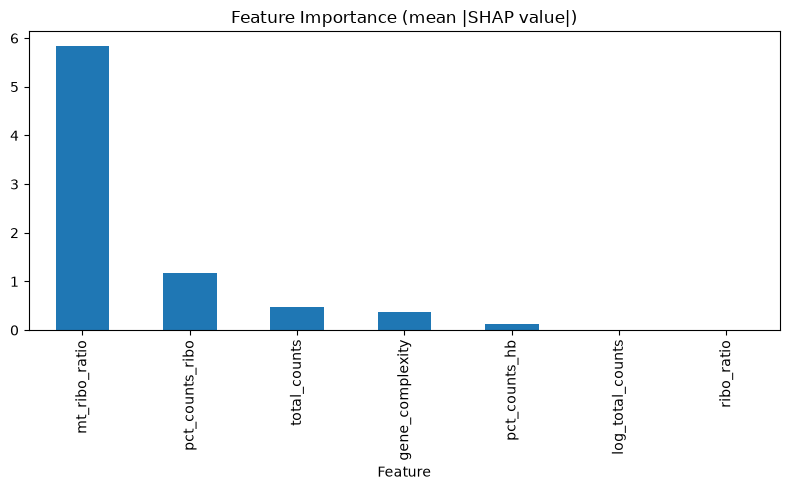

In [35]:
# Feature importance table
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'MeanAbsSHAP': np.abs(shap_values).mean(0)
}).sort_values('MeanAbsSHAP', ascending=False)

print(importance_df)
importance_df.plot.bar(x='Feature', y='MeanAbsSHAP', figsize=(8, 5), legend=False)
plt.title('Feature Importance (mean |SHAP value|)')
plt.tight_layout()
plt.show()

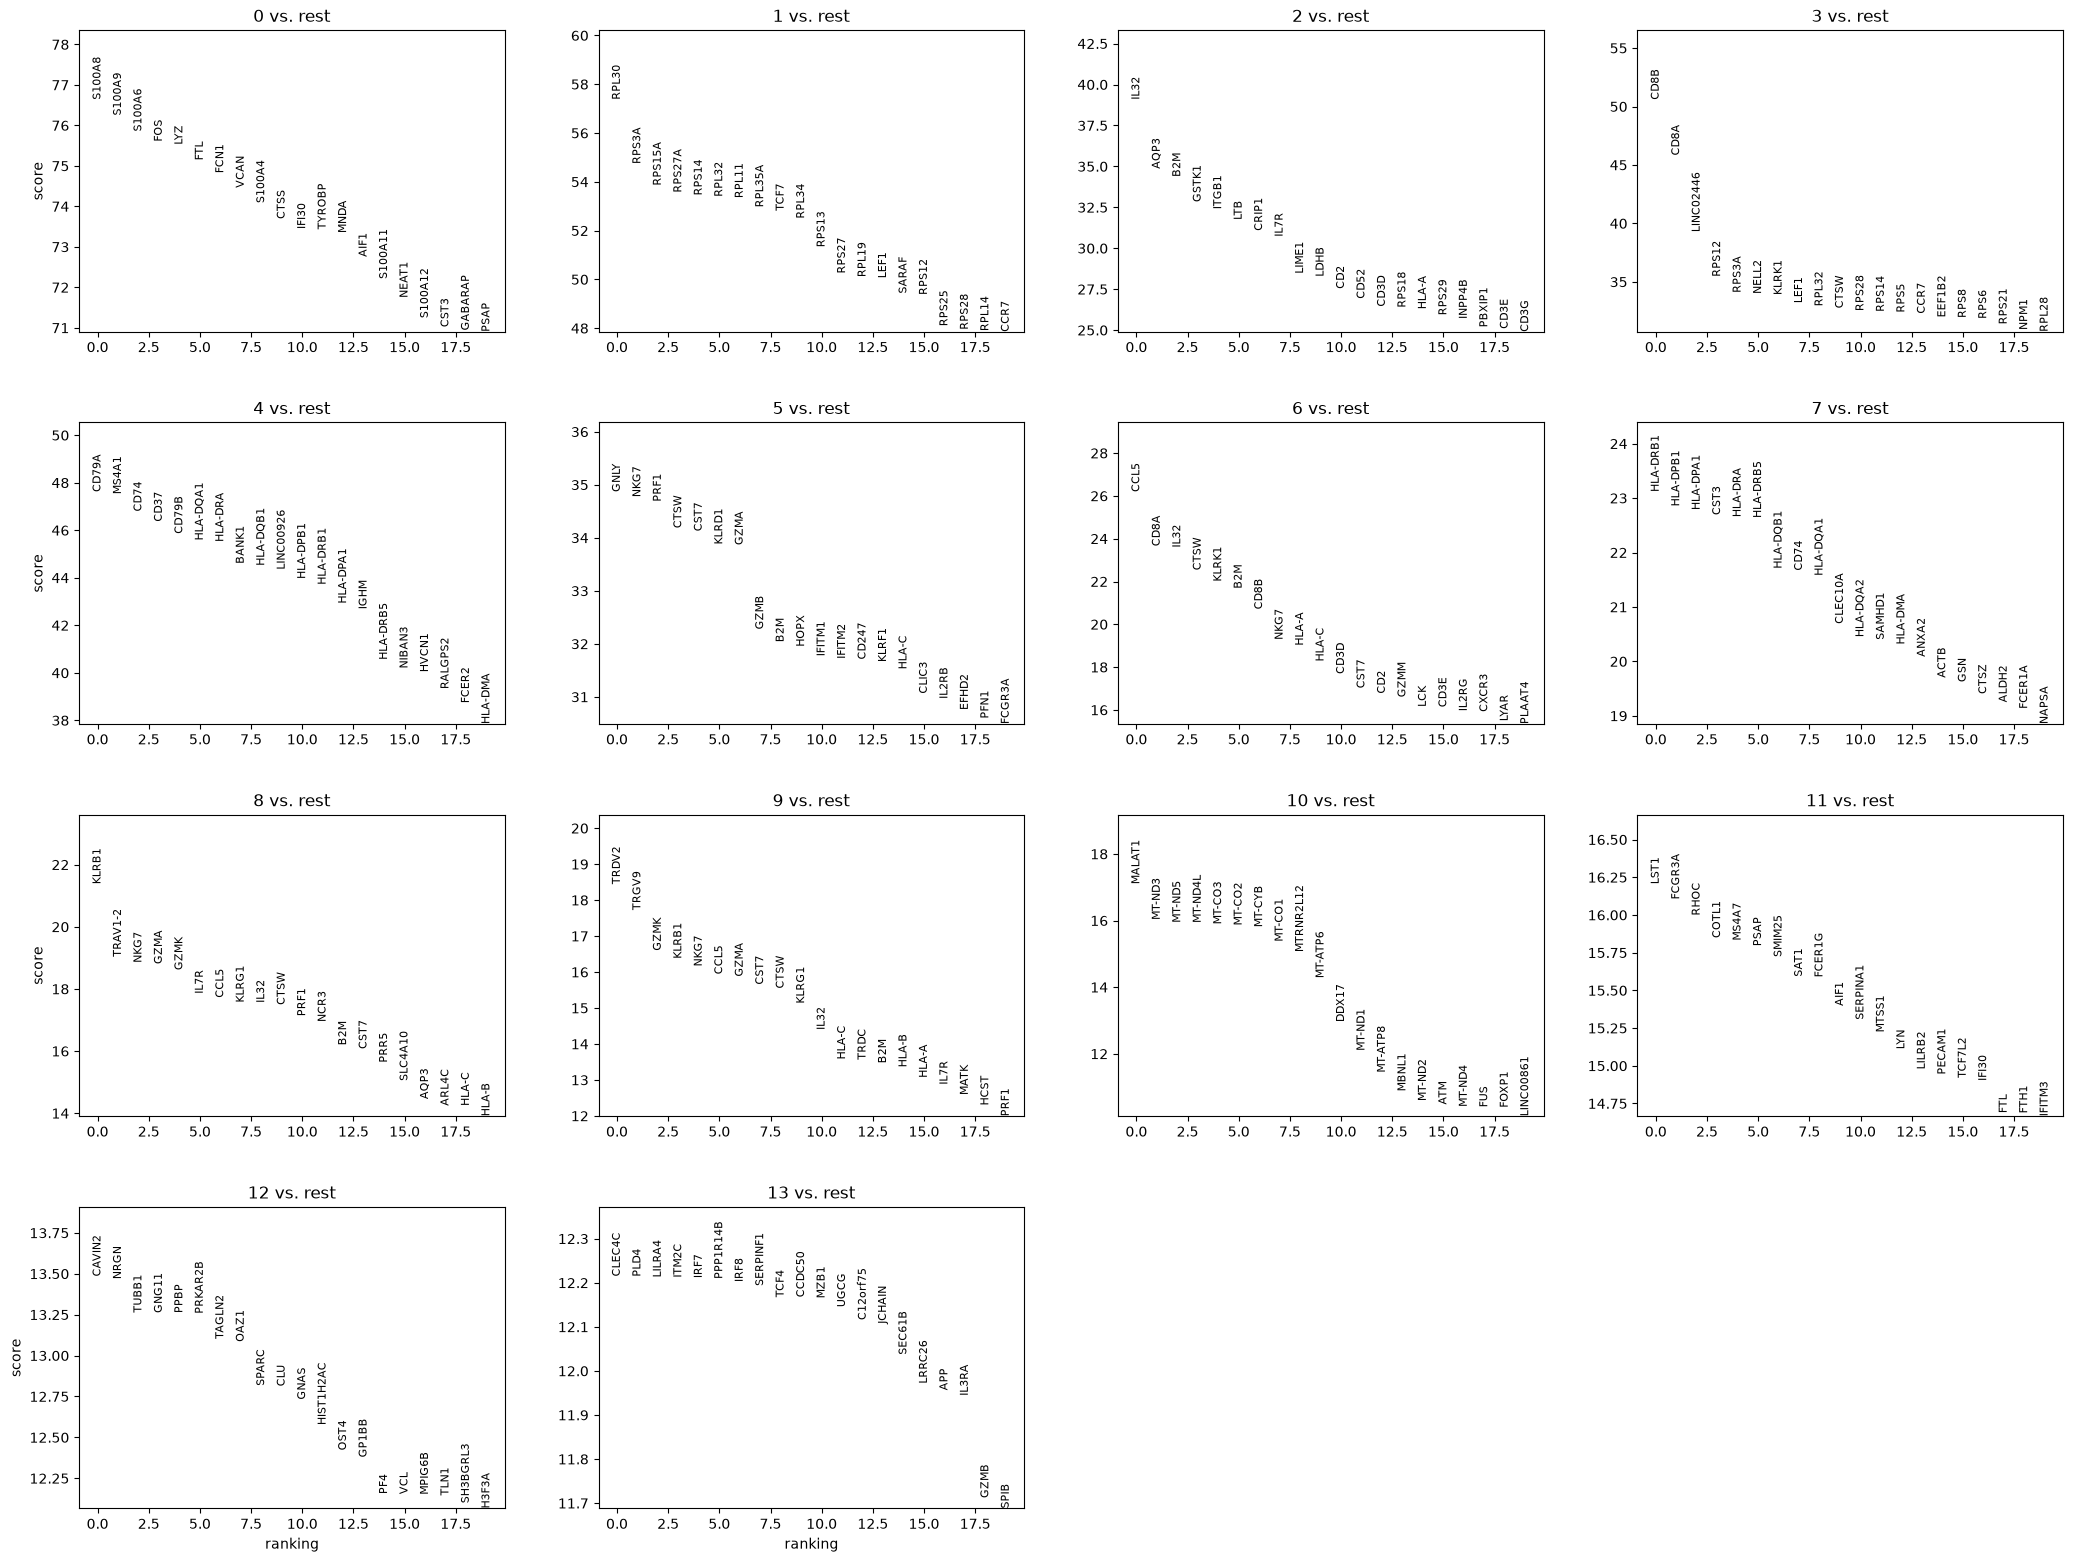

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,S100A8,76.634369,9.880153,0.0,0.0
1,0,S100A9,76.244507,8.957598,0.0,0.0
2,0,S100A6,75.849808,3.872590,0.0,0.0
3,0,FOS,75.599464,5.572316,0.0,0.0
4,0,LYZ,75.522774,8.447446,0.0,0.0
5,0,FTL,75.136787,3.294738,0.0,0.0
6,0,FCN1,74.820175,7.416086,0.0,0.0
7,0,VCAN,74.457832,7.773813,0.0,0.0
8,0,S100A4,74.081696,3.911924,0.0,0.0
9,0,CTSS,73.689049,4.669169,0.0,0.0


In [36]:
sc.tl.rank_genes_groups(adata, groupby='leiden', method='wilcoxon')
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False)

marker_df = sc.get.rank_genes_groups_df(adata, group=None)
marker_df.to_csv('Marker_Genes.csv', index=False)
marker_df.head(20)

In [37]:
%pip install gseapy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import gseapy as gp

# Take top marker genes across clusters (adjust group / n as needed)
top_genes = (marker_df.sort_values('pvals_adj')
                       .groupby('group')['names']
                       .head(20)
                       .unique()
                       .tolist())

go_results = gp.enrichr(gene_list=top_genes, gene_sets='GO_Biological_Process_2021',
                        outdir=None, organism='human')
kegg_results = gp.enrichr(gene_list=top_genes, gene_sets='KEGG_2021_Human',
                          outdir=None, organism='human')
reactome_results = gp.enrichr(gene_list=top_genes, gene_sets='Reactome_2022',
                              outdir=None, organism='human')

print(go_results.results.head(10))
print(kegg_results.results.head(10))
print(reactome_results.results.head(10))

                     Gene_set  \
0  GO_Biological_Process_2021   
1  GO_Biological_Process_2021   
2  GO_Biological_Process_2021   
3  GO_Biological_Process_2021   
4  GO_Biological_Process_2021   
5  GO_Biological_Process_2021   
6  GO_Biological_Process_2021   
7  GO_Biological_Process_2021   
8  GO_Biological_Process_2021   
9  GO_Biological_Process_2021   

                                                Term Overlap       P-value  \
0  SRP-dependent cotranslational protein targetin...   30/90  5.604683e-37   
1               cytoplasmic translation (GO:0002181)   29/93  8.774936e-35   
2  cotranslational protein targeting to membrane ...   29/94  1.257449e-34   
3               protein targeting to ER (GO:0045047)  29/103  2.629829e-33   
4  nuclear-transcribed mRNA catabolic process, no...  29/113  5.396846e-32   
5          peptide biosynthetic process (GO:0043043)  30/162  1.790328e-28   
6  nuclear-transcribed mRNA catabolic process (GO...  29/171  2.168911e-26   
7           

In [39]:
print(adata_qc_all.shape)  # should show (10529, 20226) to confirm you're in the right notebook

(10529, 20226)


In [40]:
kegg_results = gp.enrichr(gene_list=top_genes, gene_sets='KEGG_2021_Human',
                          outdir=None, organism='human')
reactome_results = gp.enrichr(gene_list=top_genes, gene_sets='Reactome_2022',
                              outdir=None, organism='human')

print(kegg_results.results.head(10))
print(reactome_results.results.head(10))

          Gene_set                                 Term Overlap       P-value  \
0  KEGG_2021_Human                             Ribosome  29/158  1.977370e-27   
1  KEGG_2021_Human                  Coronavirus disease  30/232  1.113911e-23   
2  KEGG_2021_Human           Hematopoietic cell lineage   21/99  1.594111e-21   
3  KEGG_2021_Human            Graft-versus-host disease   15/42  1.588146e-19   
4  KEGG_2021_Human  Antigen processing and presentation   18/78  2.548102e-19   
5  KEGG_2021_Human                  Allograft rejection   14/38  1.576673e-18   
6  KEGG_2021_Human             Type I diabetes mellitus   14/43  1.218661e-17   
7  KEGG_2021_Human                            Phagosome  21/152  1.816602e-17   
8  KEGG_2021_Human           Autoimmune thyroid disease   14/53  3.398547e-16   
9  KEGG_2021_Human                    Viral myocarditis   14/60  2.294170e-15   

   Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  \
0      3.974513e-25            0      

In [41]:
print(reactome_results.results.head(10))

        Gene_set                                               Term  Overlap  \
0  Reactome_2022     Eukaryotic Translation Elongation R-HSA-156842    28/90   
1  Reactome_2022              Peptide Chain Elongation R-HSA-156902    27/86   
2  Reactome_2022             Selenocysteine Synthesis R-HSA-2408557    26/90   
3  Reactome_2022     Eukaryotic Translation Termination R-HSA-72764    26/90   
4  Reactome_2022                Viral mRNA Translation R-HSA-192823    26/90   
5  Reactome_2022  Nonsense Mediated Decay (NMD) Independent Of E...    26/92   
6  Reactome_2022                         Immune System R-HSA-168256  83/1943   
7  Reactome_2022  SRP-dependent Cotranslational Protein Targetin...   27/108   
8  Reactome_2022  L13a-mediated Translational Silencing Of Cerul...   27/108   
9  Reactome_2022  GTP Hydrolysis And Joining Of 60S Ribosomal Su...   27/109   

        P-value  Adjusted P-value  Old P-value  Old Adjusted P-value  \
0  1.415324e-33      7.048314e-31            0 

In [42]:
results_df.to_csv('Model_Comparison_multiome.csv', index=False)
importance_df.to_csv('Feature_Importance_multiome.csv', index=False)
adata.write('AI_Powered_scRNAseq_Final_multiome.h5ad')

print("Pipeline completed successfully.")

Pipeline completed successfully.


In [43]:
adata.obs['cell_quality'] = adata_qc_all.obs.loc[adata.obs_names, 'cell_quality']

pd.crosstab(adata.obs['cell_type'], adata.obs['cell_quality'])

cell_quality,Good
cell_type,
CD16+ NK cells,427
CD8a/a,54
Classical monocytes,2823
DC1,19
DC2,144
MAIT cells,286
Megakaryocytes/platelets,62
Memory B cells,216
Naive B cells,624


In [46]:
cols=['total_counts','pct_counts_ribo','pct_counts_hb','gene_complexity',
      'log_total_counts','ribo_ratio','mt_ribo_ratio','cell_quality']
adata_qc_all.obs[cols].to_csv('features_B.csv')